In [1]:
# General imports
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import uniform
from qadence import *
from torch import nn, optim, tensor, zeros_like, ones_like, linspace, manual_seed, tan, reshape, exp, cos
from torch.autograd import grad

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
INFO  2024-07-06 16:41:53 - pyqtorch: PyQTorch logger successfully setup with log level 20


In [2]:
manual_seed(404) #  random seed
N_QUBITS, DEPTH, LEARNING_RATE, N_POINTS = 6, 5, 0.01, 20

In [3]:
ansatz = hea(n_qubits=N_QUBITS, depth=DEPTH, operations = [RZ, RX, RZ])

#Define custom feature map scaling
def tower(i : int) -> int | float:
    return 2*i

#This feature map is the chebyshev tower map
fm = feature_map(n_qubits=N_QUBITS, param="x", fm_type = BasisSet.CHEBYSHEV, op = RY, reupload_scaling=tower)
print(fm)

#Define the Hamiltonian 
obs = hamiltonian_factory(N_QUBITS, detuning = Z)
print(obs)

#Define the quantum neural network
circuit = QuantumCircuit(N_QUBITS, chain(fm, ansatz))
model = QNN(circuit=circuit, observable=obs, inputs=["x"])

#Define the optimizer
opt = optim.Adam(model.parameters(), lr=LEARNING_RATE)

#Define analytical solution for regularized ODE
def u(x):
    return exp(-8*0.1*x)*cos(8*x)

#Define the loss function and include floating boundary point handling
def loss_fn(inputs: tensor, outputs: tensor) -> tensor:
    dfdx = grad(inputs=inputs, outputs=outputs.sum(), create_graph=True)[0]
    f = 8*outputs*(0.1 + tan(8*inputs))

    ode_loss = (dfdx + f).pow(2)
    boundary_loss = (1*ones_like(inputs) - model(zeros_like(inputs))).pow(2)
    return ode_loss.mean() + 50*boundary_loss.mean()

for epoch in range(1000):
    opt.zero_grad()

    # the collocation points are sampled randomly
    cp = linspace(0, 0.9, N_POINTS, requires_grad=True)
    cp = reshape(cp, (N_POINTS,1))

    loss = loss_fn(inputs=cp, outputs=model(cp))
    
    if (epoch % 50 == 0):
        print(epoch, loss.item())
        
    loss.backward()
    opt.step()


KronBlock(0,1,2,3,4,5) [tag: Custom Chebyshev FM]
├── RY(0) [params: [0.0]]
├── RY(1) [params: ['2*acos(x)']]
├── RY(2) [params: ['4*acos(x)']]
├── RY(3) [params: ['6*acos(x)']]
├── RY(4) [params: ['8*acos(x)']]
└── RY(5) [params: ['10*acos(x)']]


AddBlock(0,1,2,3,4,5)
├── [mul: 1.000] 
│   └── Z(0)
├── [mul: 1.000] 
│   └── Z(1)
├── [mul: 1.000] 
│   └── Z(2)
├── [mul: 1.000] 
│   └── Z(3)
├── [mul: 1.000] 
│   └── Z(4)
└── [mul: 1.000] 
    └── Z(5)
0 229.78553117208662
50 2.3815877528633735
100 0.9867080596368127
150 0.6223470501844297
200 0.34616734884366296
250 0.17701763607708093


KeyboardInterrupt: 

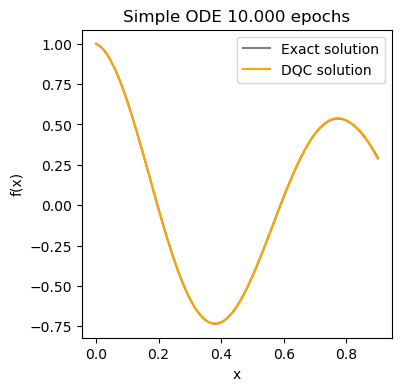

In [ ]:
sample_points = linspace(0, 0.9, steps=100).reshape(-1, 1)
analytic_sol = exp(-8*0.1*sample_points)*cos(8*sample_points)

dqc_sol = model(sample_points).detach().numpy()
x_data = sample_points.detach().numpy()

plt.figure(figsize=(4, 4))
plt.plot(x_data, analytic_sol.flatten(), color="gray", label="Exact solution")
plt.plot(x_data, dqc_sol.flatten(), color="orange", label="DQC solution")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Simple ODE 1000 epochs")
plt.savefig("simple_ode_1000.png")
plt.legend()
plt.show()